## Mock Hess diagram and color-magnitude distributions

This code can be used for testing a set of model parameters. 

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

from jjmodel.input_ import p, a, inp
from jjmodel.mwdisk import local_run, disk_builder
from jjmodel.helpers import (IMFHandler, SFRHandler, PopHandler, 
    HessConstructor, ParHandler, IFMRHandler, MSAgeHandler, extract_model_tables)  



Parameter file(s) : ok.
Number of parameters =  66 , among them technical =  7

 p(run_mode=0, out_dir='mt_best', out_mode=1, nprocess=4, Rsun=8.275, zsun=20, zmax=2000, dz=5, sigmad=31.2, sigmat=4.9, sigmag1=2.0, sigmag2=11.0, sigmadh=51.9, sigmash=0.47, td1=0, td2=7.8, dzeta=0.58, eta=5.02, pkey=1, tt1=0.1, tt2=4, gamma=2, beta=3.5, imfkey=0, a0=1.04, a1=1.61, a2=2.94, a3=2.28, m0=0.5, m1=1.5, m2=6.0, dFeHdt=0, n_FeHdt=1, fehkey=0, FeHd0=-0.7, FeHdp=0.29, rd=0.34, q=-0.72, FeHt0=-0.94, FeHtp=0.04, rt=0.77, t0=0.97, FeHsh=-1.5, dFeHsh=0.4, n_FeHsh=5, alpha=0.375, sige=26.0, sigt=45, sigdh=140, sigsh=100, sigmap=array([3.44, 1.3 ]), tpk=array([10.58, 12.5 ]), dtp=array([0.7 , 0.25]), sigp=array([26.3, 12.6]))

Parameters checked: 0 Reminders, 0 Warnings, 0 Errors.

Configuration finished:  0h 0m 0.01s


In [2]:
# Specify parameters of the simulation 
# ------------------------------------------------------------

mode_iso = {'wd':'LPCODE'}   # isochrone set 'main':'Padova',
mode_label = '-'.join(mode_iso.values())
phot = 'GaiaDR3'

mag_range = [[-0.5,1.65],[-5,18.5]]  # color-absmag range, do not change
mag_step = [0.02,0.2]                # color-absmag resolution, do not change
mag_smooth = [0.06,0.8]              # color-absmag smoothing in the model, do not change


In [3]:
# Create color-magnitude grid

col_binsc = np.arange(mag_range[0][0]+mag_step[0]/2,mag_range[0][1]+mag_step[0]/2,mag_step[0])
mag_binsc = np.arange(mag_range[1][0]+mag_step[1]/2,mag_range[1][1]+mag_step[1]/2,mag_step[1])

In [4]:
disk_builder(p,a,inp)

Results of this run will be saved to already existing folder output/Rsun8.275_mt_best

Output directory tree created.

---Local run---



Input data saved.

Output data saved.

---Local run ended sucessfully---



In [5]:
imf_handler = IMFHandler(p)
ifmr_handler = IFMRHandler(a)
sfr_handler = SFRHandler(p, a, inp)
pop_handler = PopHandler(p, a, inp)
msage_handler = MSAgeHandler()

# Define reference SFR and IMF (default parameters from SJ21)
SFR_ref = sfr_handler.create_reference_sfr()
imf_ref, (mass_binsc, IMF_ref) = imf_handler.create_reference_imf()

# Create stellar assemblies (reference) tables 
# (predictions for the reference SFR, IMF, Cummings+18 IFMR, 
# and DA fraction 0.8 without Teff dependence)
pop_tabs_ref = pop_handler.create_reference_pop_tabs(imf_ref,mode_iso,phot,FeH_scatter=0.07,Nmet_dt=7,wd='ms+wd')
pop_tabs_ref = pop_handler.create_reference_columns(pop_tabs_ref,['N', 'Mini', 'age', 't_cool'])

# Prepare position index columns for the reference ages and initial masses
indt, indm = pop_handler.get_age_mass_idx(pop_tabs_ref,mass_binsc)

# Find DA/DB WD position indices
# idx_wd refers to WD, idx_ms - to all other stars
ind_wd = pop_handler.make_wd_idx_dict(pop_tabs_ref) # separated into DA and DB tables
idx_wd, idx_ms = pop_handler.separate_wd_ms_idx(pop_tabs_ref,ind_wd) # here WD are all together

# Find position indices of CMD-defined populations:
# white dwarfs, giants, main sequence (MS), upper MS, and lower MS
idx_pop = pop_handler.split_into_pops(pop_tabs_ref)
idx_pop_combined = pop_handler.combine_pops_indices(pop_tabs_ref,idx_pop)


In [6]:
# Choose parameters that you want to test
# ------------------------------------------
par_optim = {
    'ifmr':         ['b1','alpha1','alpha2','alpha3','m_br1','m_br2'], 
    'dcool':        ['alpha_cool'],
    'f_dadb':       ['f_da'],
    'sfr': {'d':    ['dzeta','eta','sigmad','sigmap0','tpk0']}, 
    'imf':          ['a0', 'a1', 'a2','m0','m1']
}

par_handler = ParHandler(par_optim)
labels = par_handler.get_flat_param_list()

# And specify their values:

# Use this line for the default model
#params = params_mean # SJ21

# -----------------------------------------------
# Final converged simulations 
# -----------------------------------------------
params = [5.080e-01, 9.800e-02, 1.810e-01, 8.430e-02, 2.800e+00, 3.650e+00,
          1.700e-02, 7.700e-01, 5.800e-01, 5.020e+00, 3.120e+01, 3.440e+00,
          1.058e+01, 1.040e+00, 1.610e+00, 2.940e+00, 5.000e-01, 1.500e+00]  # pop14long_lpcode

#params = [5.040e-01, 9.600e-02, 1.810e-01, 8.380e-02, 2.810e+00, 3.650e+00,
#          1.100e-02, 7.700e-01, 5.600e-01, 4.970e+00, 3.130e+01, 3.430e+00,
#          1.065e+01, 1.040e+00, 1.600e+00, 2.940e+00, 5.000e-01, 1.500e+00] # pop14long_basti

#params = [0.51, 0.098, 0.181, 0.0842, 2.8, 3.65, 0.001, 
#          0.78, 0.56, 4.89, 31.6, 3.51, 10.55, 1.05, 1.62, 2.9, 0.5, 1.5]   # pop14long_montreal

param_struct = par_handler.fill_param_struct(params)


In [7]:

# Add new SFR and IMF to kwargs if their parameters are varied 
if 'sfr' in param_struct.keys():
    inp, SFR_new = sfr_handler.update_sfr(**param_struct['sfr'])

if 'imf' in param_struct.keys():
    _, (_, IMF_new) = imf_handler.update_imf(**param_struct['imf'])

# Run the model locally and extract its output tables (potential, scale heights, etc)
out = local_run(p,a,inp,save=True,status_progress=False)
inp_tabs = extract_model_tables(out,inp)

# Update number densities of the stellar assemblies
pop_tabs, indt = pop_handler.update_pop_tabs(
    param_struct,
    pop_tabs_ref,
    **{'SFR_new':SFR_new,
       'IMF_new':IMF_new,
       'SFR_ref':SFR_ref,
       'IMF_ref':IMF_ref,
       'indt':indt,
       'indm':indm,
       'ind_wd':ind_wd,
       'ind_pop':idx_pop_combined,
       'ifmr_handler':ifmr_handler,
       'msage_handler':msage_handler
       })

# Save updated tables
for key in pop_tabs.keys():
    pop_tabs[key].write(a.T['poptab']+f'/SSP_R{p.Rsun}_{key}_{mode_label}.csv',overwrite=True)


In [8]:
# Generate Hess diagram

d_max = 100
constructor = HessConstructor(p, a, mag_range, mag_step,r_max=d_max)

# Total Hess diagram
hess_tot = constructor.generate_hess(
    pop_tabs,
    indt['d'],
    inp_tabs,
    mag_range,
    mag_step,
    mag_smooth,
    volume='sphere',
    )


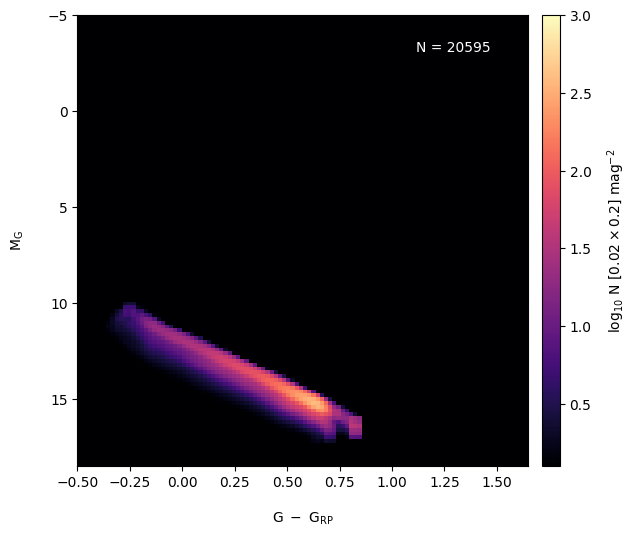

In [9]:
# Plot Hess diagram

Ntot_m = int(round(sum(sum(hess_tot)),0))

fig, ax = plt.subplots(1,1,figsize=(7,5.5),sharey=True)

im = ax.imshow(np.log10(hess_tot+1),interpolation=None,cmap=mpl.colormaps['magma'],
               extent=[mag_range[0][0],mag_range[0][1],mag_range[1][1],mag_range[1][0]],
               vmin=0.1,vmax=3)
ax.set_aspect(abs((mag_range[0][1]-mag_range[0][0])/(mag_range[1][1]-mag_range[1][0])))
ax.text(0.75,0.92,'N = '+str(Ntot_m),color='w',transform=ax.transAxes)
ax.set_xlabel(r'$\mathrm{G \ - \ G_{RP}}$',labelpad=15)
ax.set_ylabel(r'$\mathrm{M_G}$',labelpad=15)

fig.subplots_adjust(left=0.05,wspace=0.05,right=0.8,top=0.93)
pos = ax.get_position()
cax = fig.add_axes([pos.x0+pos.width+0.02,pos.y0,0.025,pos.height])
cbar = fig.colorbar(im,cax=cax,orientation='vertical')
cbar.set_label(r'$\mathrm{log_{10} \ N \ [' + str(mag_step[0]) +
               r'\times' + str(mag_step[1]) + r'] \ mag^{-2}}$',labelpad=10)
